<a href="https://colab.research.google.com/github/tristanwalmsley/CO3519_Artificial-Intelligence_Lab5_Facial-Emotion-Recognition/blob/main/AI_Lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import cv2
import numpy as np
import os
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from google.colab import drive
drive.mount('/content/drive')

face_cascade = cv2.CascadeClassifier("/content/drive/My Drive/haarcascade_frontalface_default.xml")

def load_and_detect_faces(folder_path):
  images = []
  labels = []
  for label in os.listdir(folder_path):
    label_path = os.path.join(folder_path, label)
    if os.path.isdir(label_path):
      for img_file in os.listdir(label_path):
        img_path = os.path.join(label_path, img_file)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        if img is not None:
          faces = face_cascade.detectMultiScale(img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
          for (x, y, w, h) in faces:
            face_region = img[y:y+h, x:x+w]
            images.append(face_region)
            labels.append(label)
  return images, labels

train_folder_path = "/content/drive/My Drive/CK_dataset/train"
test_folder_path = "/content/drive/My Drive/CK_dataset/test"

X_train, y_train = load_and_detect_faces(train_folder_path)
X_test, y_test = load_and_detect_faces(test_folder_path)

def preprocess_images(images):
  preprocessed_images = []
  for img in images:
    img = cv2.equalizeHist(img)
    preprocessed_images.append(img)
  return preprocessed_images

X_train_preprocessed = preprocess_images(X_train)
X_test_preprocessed = preprocess_images(X_test)

# Upgraded LBP parameters for richer textural detail
radius = 2
n_points = 8 * radius  # 16 points

def extract_lbp_features(images):
  lbp_features = []
  for img in images:
    img = cv2.resize(img, (64, 64))
    lbp = local_binary_pattern(img, n_points, radius, method="uniform")
    (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))
    hist = hist.astype("float")
    hist /= (hist.sum() + 1e-6)
    lbp_features.append(hist)
  return np.array(lbp_features)

X_train_features = extract_lbp_features(X_train_preprocessed)
X_test_features = extract_lbp_features(X_test_preprocessed)

# Re-train SVM classifier with optimized parameters for the new 18-dim feature set
svm_classifier = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma='scale', class_weight='balanced'))

svm_classifier.fit(X_train_features, y_train)
y_pred = svm_classifier.predict(X_test_features)

accuracy = accuracy_score(y_test, y_pred)
print(f"New Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Total Test Samples: {len(y_test)}")
print("Classifier Classes Order:", svm_classifier.classes_)
print("Confusion Matrix:\n", conf_matrix)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
New Accuracy: 34.69%

Classification Report:
              precision    recall  f1-score   support

       anger       0.22      0.14      0.17        14
        fear       0.00      0.00      0.00         7
   happiness       0.57      0.57      0.57        21
     neutral       0.47      0.38      0.42        24
     sadness       0.17      0.25      0.20         8
    surprise       0.31      0.38      0.34        24

    accuracy                           0.35        98
   macro avg       0.29      0.29      0.28        98
weighted avg       0.36      0.35      0.35        98

Total Test Samples: 98
Classifier Classes Order: ['anger' 'fear' 'happiness' 'neutral' 'sadness' 'surprise']
Confusion Matrix:
 [[ 2  2  1  3  4  2]
 [ 0  0  1  0  1  5]
 [ 1  2 12  0  2  4]
 [ 3  2  2  9  1  7]
 [ 0  0  1  3  2  2]
 [ 3  2  4  4  2  9]]


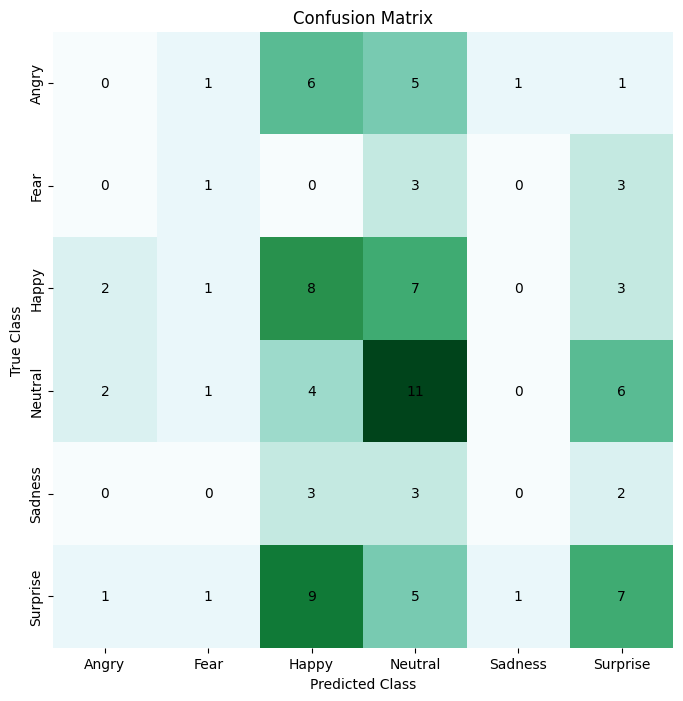

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score

class_names = ["Angry", "Fear", "Happy", "Neutral", "Sadness", "Surprise"]

conf_matrix = confusion_matrix(y_test, y_pred)

conf_matrix_percent = conf_matrix / conf_matrix.sum(axis=1, keepdims=True) * 100

plt.figure(figsize=(8, 8))
ax = sns.heatmap(conf_matrix, annot=False, cmap="BuGn", xticklabels=class_names, yticklabels=class_names, cbar=False)

for i in range(conf_matrix.shape[0]):
  for j in range(conf_matrix.shape[1]):
    count = conf_matrix[i, j]
    ax.text(j + 0.5, i + 0.5, f"{count}", ha="center", va="center", color="black", fontsize=10)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")
plt.show()

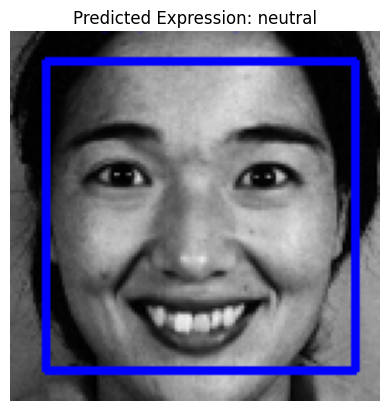

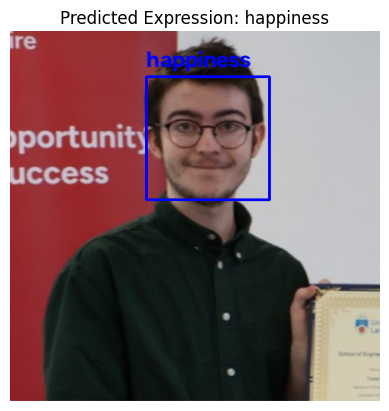

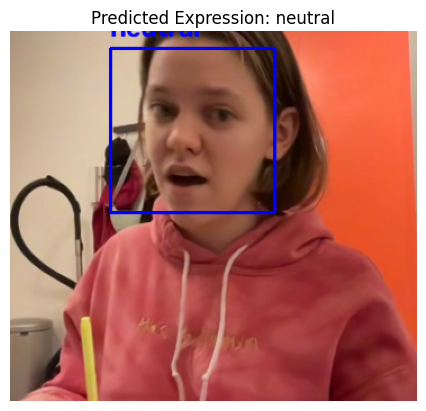

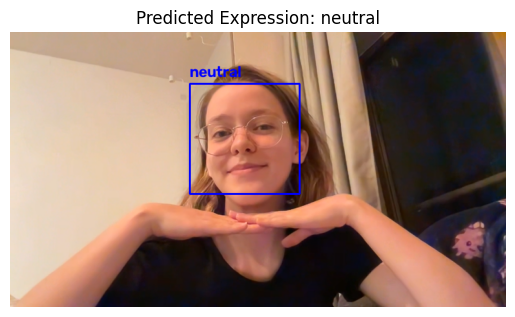

In [38]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import local_binary_pattern

# Updated to match the retrained model's upgraded LBP parameters
radius = 2
n_points = 8 * radius
face_cascade = cv2.CascadeClassifier('/content/drive/My Drive/haarcascade_frontalface_default.xml')

def preprocess_and_extract_features(face_img):
  # Apply histogram equalization to match training preprocessing
  face_img = cv2.equalizeHist(face_img)
  face_img = cv2.resize(face_img, (64, 64))

  lbp = local_binary_pattern(face_img, n_points, radius, method="uniform")

  (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, n_points + 3), range=(0, n_points + 2))

  hist = hist.astype("float")
  hist /= (hist.sum() + 1e-6)

  return hist.reshape(1, -1)

def predict_emotion(image_path, model):
  img = cv2.imread(image_path)

  if img is None:
    raise ValueError("Image not found or could not be loaded.")

  gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  faces = face_cascade.detectMultiScale(gray_img, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

  if len(faces) == 0:
    print("No face detected in the image.")
    return

  predicted_expression = "Unknown"
  for (x, y, w, h) in faces:
    face_region = gray_img[y:y+h, x:x+w]

    features = preprocess_and_extract_features(face_region)

    predicted_expression = model.predict(features)[0]

    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)
    cv2.putText(img, predicted_expression, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)

  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

  plt.imshow(img_rgb)
  plt.title(f"Predicted Expression: {predicted_expression}")
  plt.axis('off')
  plt.show()

image_path4 = "/content/drive/My Drive/test_images/27.tiff"
predict_emotion(image_path4, svm_classifier)
image_path = "/content/drive/My Drive/test_images/1.jpeg"
predict_emotion(image_path, svm_classifier)
image_path2 = "/content/drive/My Drive/test_images/2.png"
predict_emotion(image_path2, svm_classifier)
image_path3 = "/content/drive/My Drive/test_images/3.png"
predict_emotion(image_path3, svm_classifier)

In [31]:
from collections import Counter

print("Training labels distribution:", Counter(y_train))
print("Testing labels distribution:", Counter(y_test))
print("Predicted labels distribution:", Counter(y_pred))


Training labels distribution: Counter({'surprise': 59, 'neutral': 55, 'happiness': 50, 'anger': 32, 'sadness': 20, 'fear': 18})
Testing labels distribution: Counter({'neutral': 24, 'surprise': 24, 'happiness': 21, 'anger': 14, 'sadness': 8, 'fear': 7})
Predicted labels distribution: Counter({np.str_('neutral'): 34, np.str_('happiness'): 30, np.str_('surprise'): 22, np.str_('fear'): 5, np.str_('anger'): 5, np.str_('sadness'): 2})
